<br>
<font>
<div dir=ltr align=center>
<div dir=ltr align=center>
<font color=0F5298 size=7>
    Artificial Intelligence <br>
<font color=2565AE size=5>
    Computer Engineering Department <br>
    Arash Marioriyad<br>
    Spring 2026<br>
<font color=3C99D size=5>
    Practical HomeWork 2<br>
    Tic-Tac-Toe<br>
<font color=696880 size=4>
    Fateme Masoumian

`Full Name:` Sobhan Aram

# **AI Practical Assignment : Adversarial Search with Minimax and Alpha-Beta Pruning**

Welcome to your practical assignment! The goal of this exercise is to understand and implement **adversarial search algorithms** , which are fundamental to creating AI for two-player, zero-sum games like Tic-Tac-Toe, Chess, or Go.

In this notebook, you will:
1.  **Create and Visualize a Game Tree**: Understand how a game can be represented as a tree of possible moves.
2.  **Implement the Minimax Algorithm**: Write the code for the optimal recursive strategy that determines the best move by assuming the opponent plays optimally as well.
3.  **Implement Alpha-Beta Pruning**: Optimize the Minimax algorithm by intelligently "pruning" branches of the game tree that don't need to be explored.
4.  **Analyze Algorithm Performance**: Investigate how factors like move ordering can dramatically affect the efficiency of Alpha-Beta pruning.

This assignment will build directly on the concepts discussed in the lecture slides. Let's get started!


## Setup & Imports

In [1]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import string

np.random.seed(42)

# **Part 1: The Game Tree**

An adversarial game can be modeled as a tree. The **root** of the tree is the current state of the game. The **nodes** are states that can be reached, and the **edges** represent moves. The **leaf nodes** are terminal states, each with a **utility value** or score (e.g., +1 for a win, -1 for a loss, 0 for a draw).

Our goal is to find the best possible move from the current state. We will work with two players:
*   **MAX player (▲)**: Tries to maximize the score.
*   **MIN player (▼)**: Tries to minimize the score.

We'll start by creating a function to generate a random game tree and another function to visualize it.

## Tree Creation and Visualization

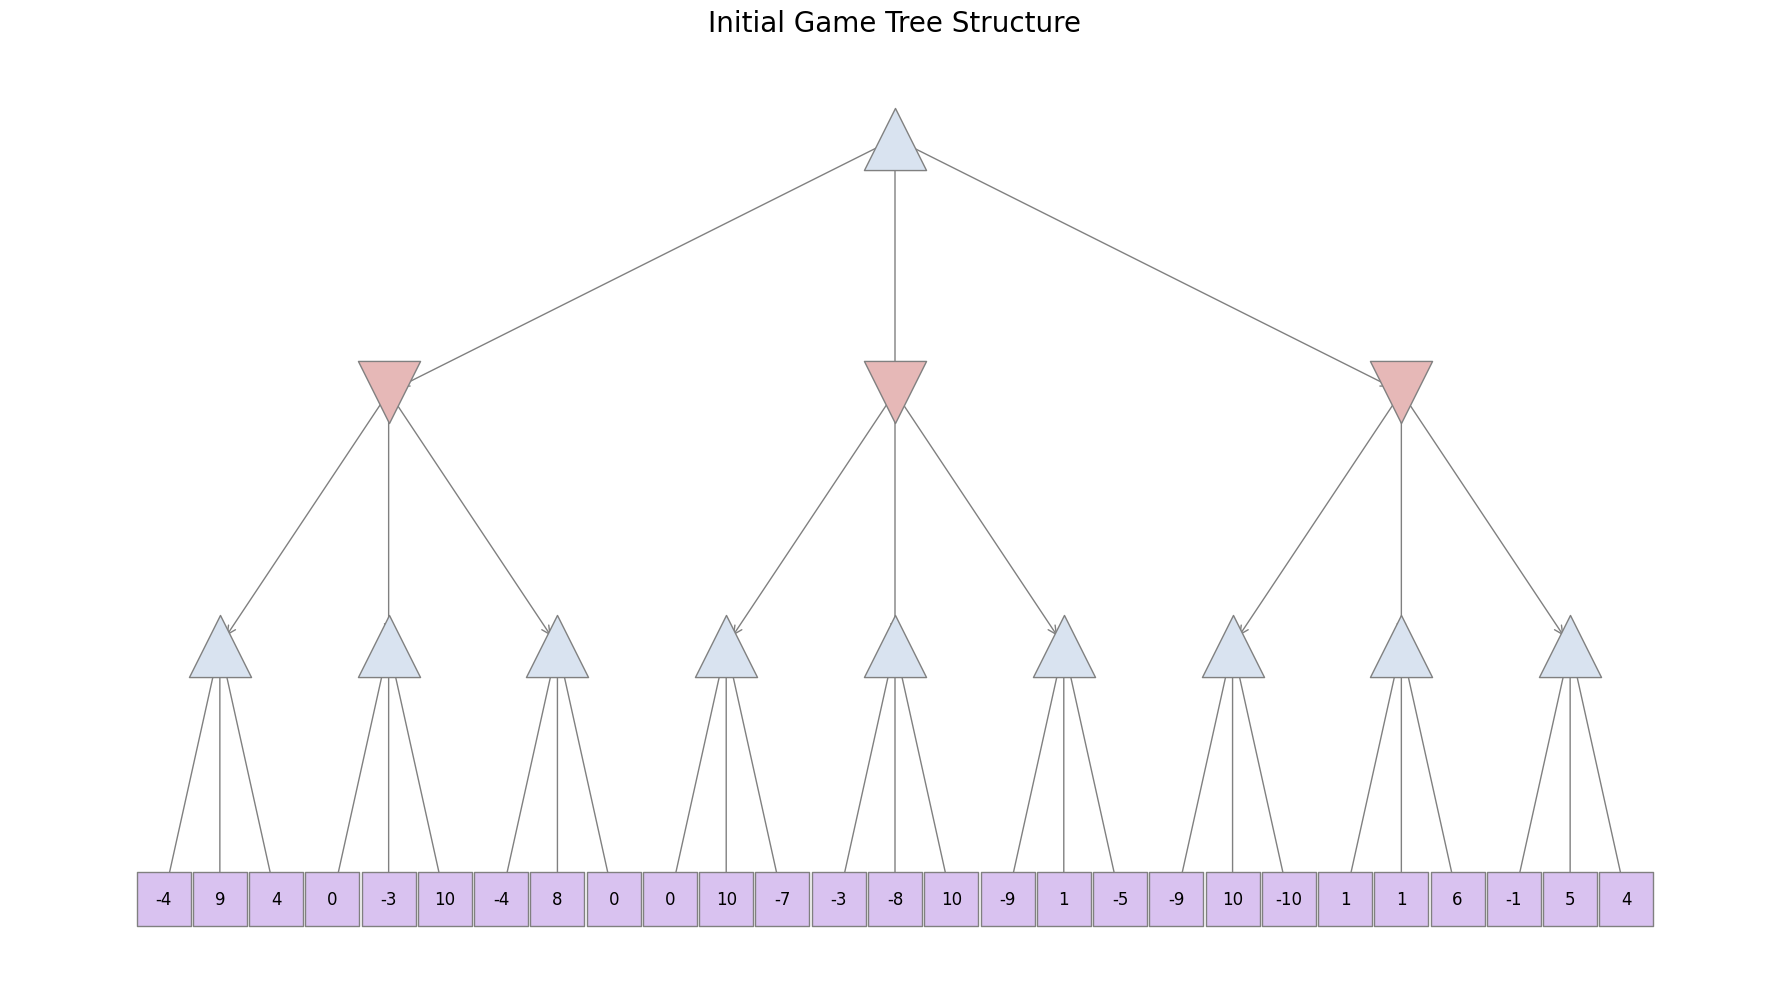

In [2]:
def create_game_tree(depth, branching_factor):
    """Creates a game tree using NetworkX."""
    G = nx.DiGraph()


    
    def add_nodes_recursively(node_id, current_depth):
        G.add_node(node_id, depth=current_depth)
        
        if current_depth == depth:
            G.nodes[node_id]['value'] = np.random.randint(-10, 11)
            return

        for i in range(branching_factor):
            child_id = f"{node_id}-{i}"
            G.add_edge(node_id, child_id)
            add_nodes_recursively(child_id, current_depth + 1)

    add_nodes_recursively("0", 0)
    return G

def hierarchy_pos(G, root):
    """Custom hierarchical top-down layout for trees to avoid graphviz dependencies."""
    pos = {}
    dfs_nodes = list(nx.dfs_preorder_nodes(G, root))
    leaves_ordered = [n for n in dfs_nodes if G.out_degree(n) == 0]
    
    for i, leaf in enumerate(leaves_ordered):
        pos[leaf] = (i * 2, -G.nodes[leaf]['depth'] * 2)
        
    for node in reversed(dfs_nodes):
        if G.out_degree(node) > 0:
            children = list(G.successors(node))
            x = sum(pos[c][0] for c in children) / len(children)
            pos[node] = (x, -G.nodes[node]['depth'] * 2)
    return pos

def plot_game_tree(G, node_values=None, visited_nodes=None, title="Game Tree"):
    """Visualizes the game tree vertically with clear MAX/MIN/Leaf shapes."""
    plt.figure(figsize=(18, 10)) 
    
    pos = hierarchy_pos(G, "0")

    max_nodes = [n for n, d in G.nodes(data='depth') if d % 2 == 0 and G.out_degree(n) > 0]
    min_nodes = [n for n, d in G.nodes(data='depth') if d % 2 == 1 and G.out_degree(n) > 0]
    leaf_nodes = [n for n in G.nodes() if G.out_degree(n) == 0]
    
    def get_nodes(n_list, visited):
        if visited is None: return n_list
        return [n for n in n_list if n in visited]
        
    def get_unvisited(n_list, visited):
        if visited is None: return []
        return [n for n in n_list if n not in visited]

    nx.draw_networkx_edges(G, pos, arrows=True, arrowstyle='->', arrowsize=15, edge_color='gray')

   
    nx.draw_networkx_nodes(G, pos, nodelist=get_unvisited(max_nodes, visited_nodes), node_shape='^', node_color='#e0e0e0', node_size=1500, edgecolors='gray')
    nx.draw_networkx_nodes(G, pos, nodelist=get_unvisited(min_nodes, visited_nodes), node_shape='v', node_color='#e0e0e0', node_size=1500, edgecolors='gray')
    nx.draw_networkx_nodes(G, pos, nodelist=get_unvisited(leaf_nodes, visited_nodes), node_shape='s', node_color='#e0e0e0', node_size=1200, edgecolors='gray')


    nx.draw_networkx_nodes(G, pos, nodelist=get_nodes(max_nodes, visited_nodes), node_shape='^', node_color='#d9e3f0', node_size=2000, edgecolors='gray')
    nx.draw_networkx_nodes(G, pos, nodelist=get_nodes(min_nodes, visited_nodes), node_shape='v', node_color='#e6b8b7', node_size=2000, edgecolors='gray')
    nx.draw_networkx_nodes(G, pos, nodelist=get_nodes(leaf_nodes, visited_nodes), node_shape='s', node_color='#d9c2f0', node_size=1500, edgecolors='gray')

  
    labels = {}
    for n in G.nodes():
        if G.out_degree(n) == 0: 
            labels[n] = G.nodes[n]['value']
        elif node_values and n in node_values:
            labels[n] = f"{node_values[n]}"
        else:
            labels[n] = "" 

    nx.draw_networkx_labels(G, pos, labels, font_size=12, font_color='black')
    
    plt.title(title, fontsize=20, pad=20)
    plt.axis('off')
    plt.tight_layout()
    plt.show()


DEPTH = 3
BRANCHING_FACTOR = 3
game_tree = create_game_tree(DEPTH, BRANCHING_FACTOR)

plot_game_tree(game_tree, title="Initial Game Tree Structure")


# **Part 2: The Minimax Algorithm**

The Minimax algorithm performs a complete depth-first search of the game tree.
- **MAX player** chooses the move that leads to the outcome with the highest value.
- **MIN player** chooses the move that leads to the outcome with the lowest value.

Each node's value is determined by the values of its children. For a MAX node, its value is the maximum of its children's values. For a MIN node, its value is the minimum of its children's values.

**Your Task:** Implement the `minimax` function below. The function should be recursive and explore the entire tree to find the optimal value from the root. It should also track which nodes it visits.

## Minimax Implementation

Optimal value at root (Minimax): 8
Total nodes watched by Minimax: 40 out of 40


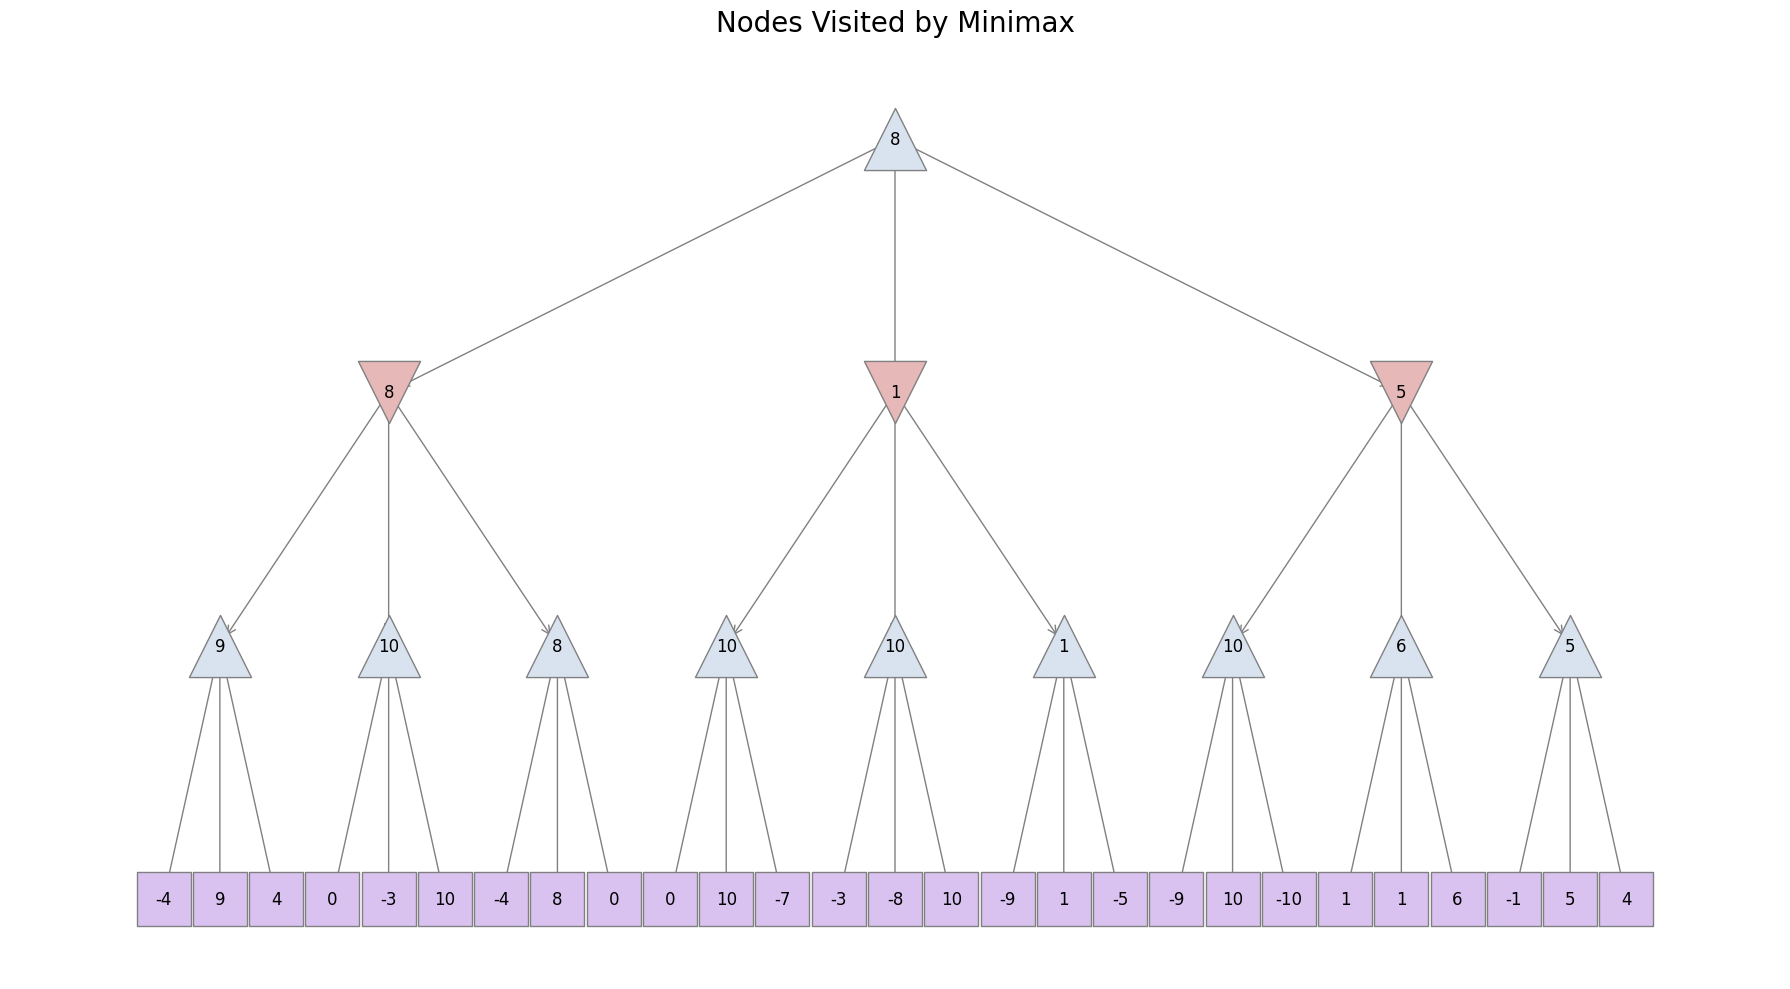

In [3]:
def minimax(graph, node, is_max_player, visited_nodes, node_values):
    """Performs the Minimax algorithm on a game tree."""
    visited_nodes.add(node)
    

    if(graph.out_degree(node) == 0):
        this_terminal_value = graph.nodes[node]['value']
        node_values[node] = this_terminal_value
        return this_terminal_value
    
    if(is_max_player):
        children = list(graph.successors(node))
        best = -float('inf')
        for child in children:
            this_child_value = minimax(graph, child, False, visited_nodes, node_values)
            if(this_child_value > best):
                best = this_child_value

        node_values[node] = best
        return best
    
    else:
        children = list(graph.successors(node))
        worst = float('inf')
        for child in children:
            this_child_value = minimax(graph, child, True, visited_nodes, node_values)
            if(this_child_value < worst):
                worst = this_child_value

        node_values[node] = worst
        return worst

        

visited_minimax = set()
values_minimax = {}
root_value_minimax = minimax(game_tree, "0", True, visited_minimax, values_minimax)

print(f"Optimal value at root (Minimax): {root_value_minimax}")
print(f"Total nodes watched by Minimax: {len(visited_minimax)} out of {len(game_tree.nodes)}")


plot_game_tree(game_tree, node_values=values_minimax, visited_nodes=visited_minimax, title="Nodes Visited by Minimax")

# **Part 3: Alpha-Beta Pruning**

As you can see, Minimax visits every single node in the tree. This is very inefficient for large games (Time Complexity: $O(b^m)$). **Alpha-Beta Pruning** is an optimization that returns the same result as Minimax but avoids searching parts of the tree it knows can't influence the final decision.

It maintains two values:
- **`alpha`**: The best value (highest) found so far for **MAX** along the path from the root to the current node.
- **`beta`**: The best value (lowest) found so far for **MIN** along the path from the root to the current node.

The key pruning condition is: **`beta <= alpha`**.
- If a **MAX** node encounters a child value greater than or equal to `beta`, it can stop searching its other children. 
- If a **MIN** node encounters a child value less than or equal to `alpha`, it can stop searching.

**Your Task:** Implement the `alpha_beta_search` function. Pay close attention to how `alpha` and `beta` are updated and passed down.

## Alpha-Beta Implementation

Optimal value at root (Alpha-Beta): 8
Total nodes watched by Alpha-Beta: 36
Nodes pruned (saved): 4


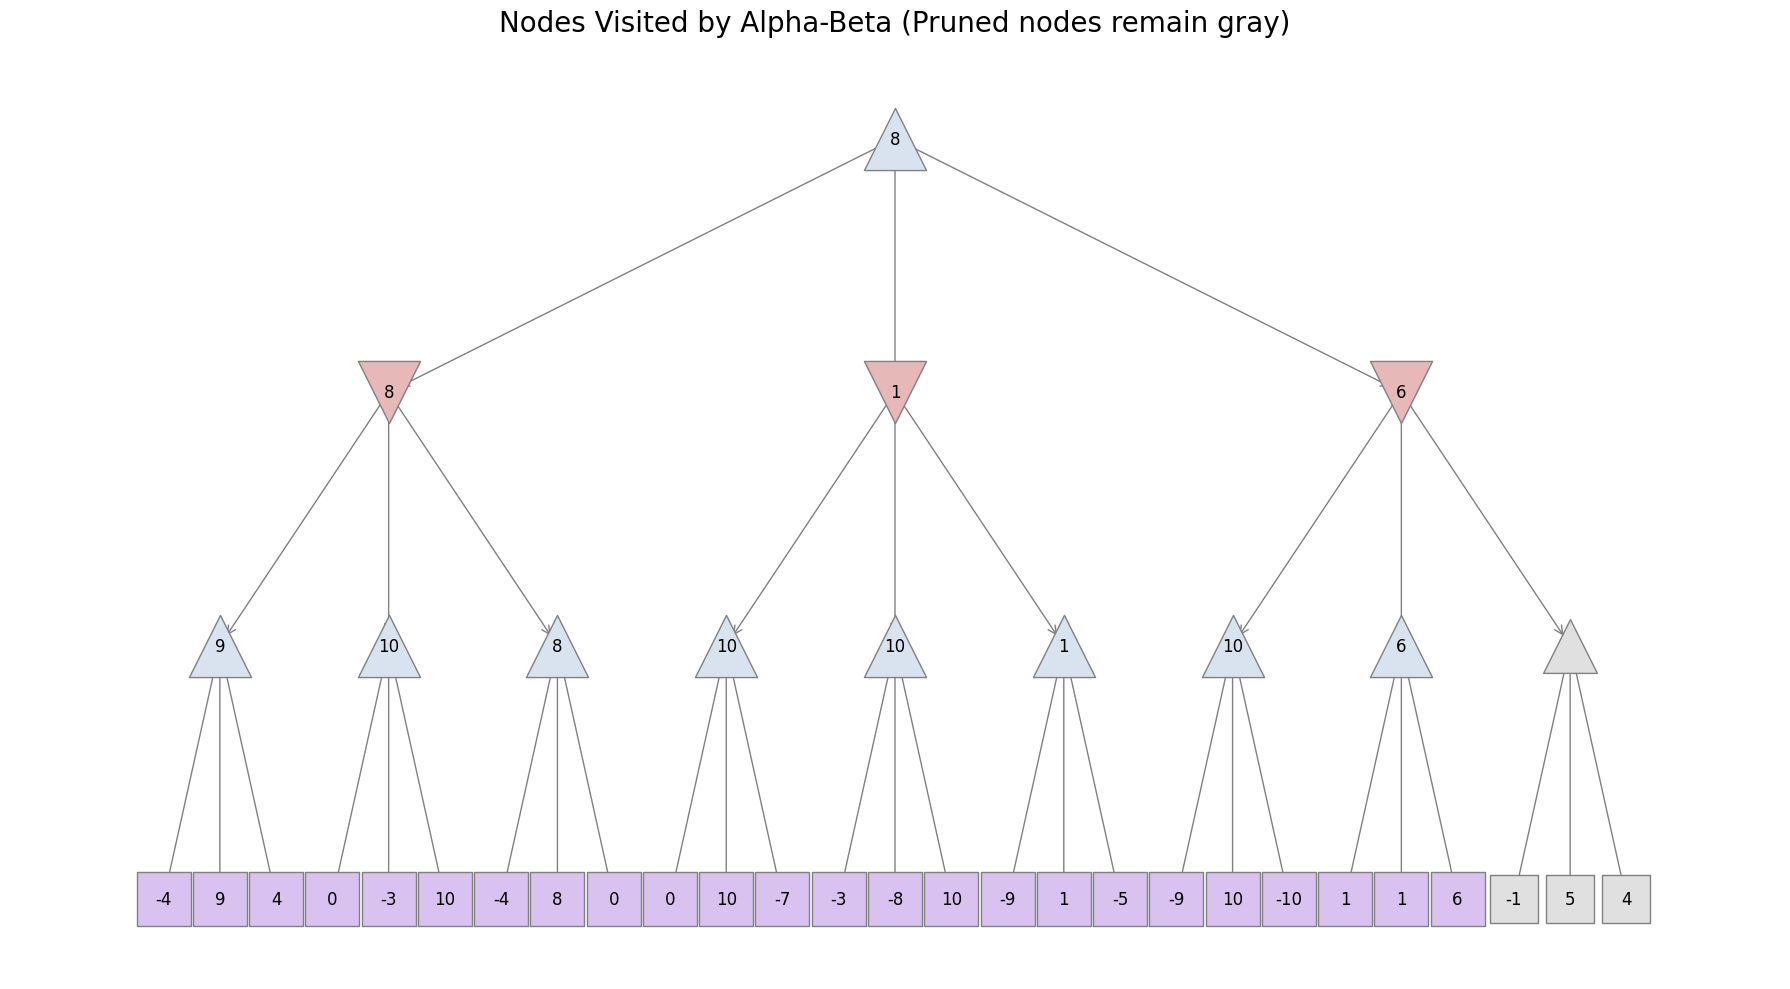

In [4]:
def alpha_beta_search(graph, node, alpha, beta, is_max_player, visited_nodes, node_values):
    """Performs the Alpha-Beta Pruning search on a game tree."""
    visited_nodes.add(node)
    
    if(graph.out_degree(node) == 0):
        this_terminal_value = graph.nodes[node]['value']
        node_values[node] = this_terminal_value
        return this_terminal_value

    if(is_max_player):
        children = list(graph.successors(node))
        best = -float('inf')
        for child in children:
            this_child_value = alpha_beta_search(graph, child, alpha, beta, False, visited_nodes, node_values)
            if(this_child_value > best):
                best = this_child_value

            if(alpha < best):
                alpha = best

            if(alpha >= beta):
                break

        node_values[node] = best
        return best
    
    else:
        children = list(graph.successors(node))
        worst = float('inf')
        for child in children:
            this_child_value = alpha_beta_search(graph, child, alpha, beta, True, visited_nodes, node_values)
            if(this_child_value < worst):
                worst = this_child_value

            if(beta > worst):
                beta = worst

            if(alpha >= beta):
                break

        node_values[node] = worst
        return worst

visited_ab = set()
values_ab = {}
root_value_ab = alpha_beta_search(game_tree, "0", -float('inf'), float('inf'), True, visited_ab, values_ab)

print(f"Optimal value at root (Alpha-Beta): {root_value_ab}")
print(f"Total nodes watched by Alpha-Beta: {len(visited_ab)}")
print(f"Nodes pruned (saved): {len(visited_minimax) - len(visited_ab)}")

# Visualize the result
plot_game_tree(game_tree, node_values=values_ab, visited_nodes=visited_ab, title="Nodes Visited by Alpha-Beta (Pruned nodes remain gray)")


# **Part 4: The Importance of Move Ordering**

The performance of Alpha-Beta pruning is highly dependent on **move ordering**. If the algorithm explores the best moves first, it can achieve maximal pruning. If it explores the worst moves first, it may not prune any branches at all.

With "perfect ordering", the time complexity can be reduced from $O(b^m)$ to roughly $O(b^{m/2})$, effectively doubling the solvable search depth.

**Your Task:** Analyze the code and the output below to see how perfect move ordering further reduces the number of visited nodes.


##  Move Ordering

--- Algorithm Performance Comparison (Nodes Watched) ---
1. Minimax visited: 40 nodes.
2. Alpha-Beta (random order) visited: 36 nodes.
3. Alpha-Beta (optimal order) visited: 20 nodes.



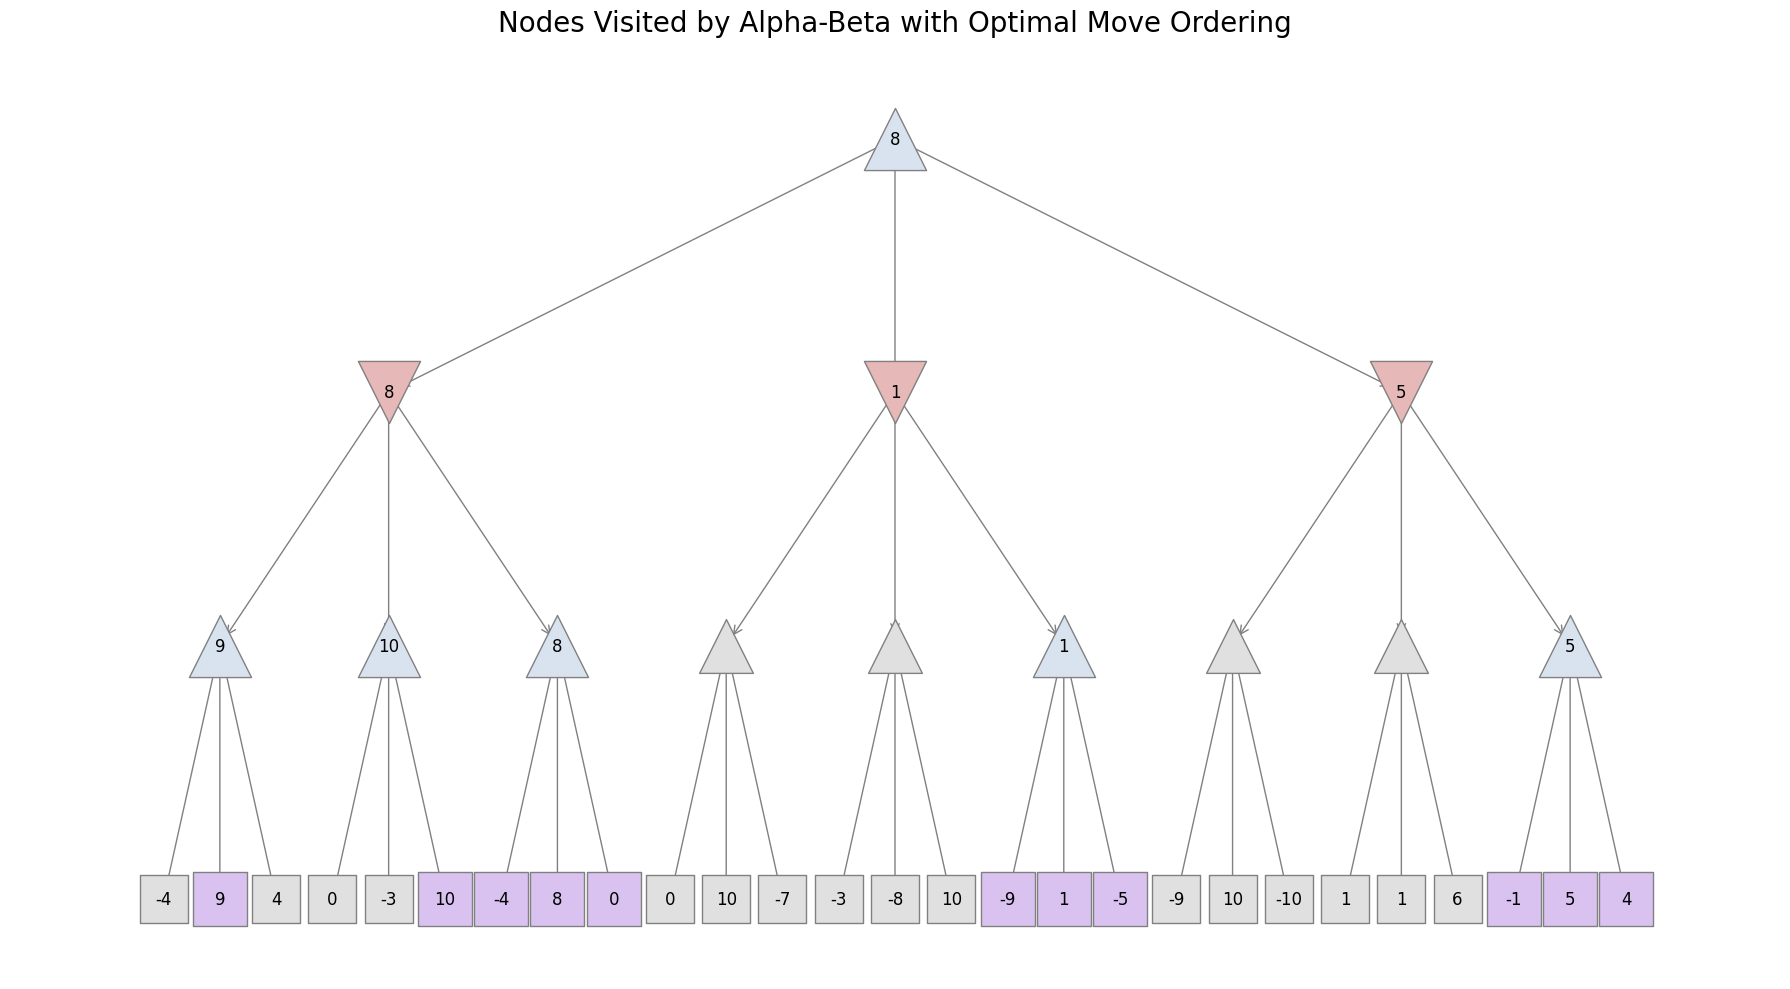

In [5]:
def get_ordered_children(graph, node, is_max_player):
    """Sorts children to demonstrate move ordering impact."""
    children = list(graph.successors(node))
    

    children.sort(key=lambda child: values_minimax[child], reverse=is_max_player)
    return children
    

def alpha_beta_ordered(graph, node, alpha, beta, is_max_player, visited_nodes, node_values):
    """Alpha-Beta search that uses a specific move ordering strategy."""
    visited_nodes.add(node)
    
    if(graph.out_degree(node) == 0):
        this_terminal_value = graph.nodes[node]['value']
        node_values[node] = this_terminal_value
        return this_terminal_value

    if(is_max_player):
        children = get_ordered_children(graph, node, True)
        best = -float('inf')
        for child in children:
            this_child_value = alpha_beta_ordered(graph, child, alpha, beta, False, visited_nodes, node_values)
            if(this_child_value > best):
                best = this_child_value

            if(alpha < best):
                alpha = best

            if(alpha >= beta):
                break

        node_values[node] = best
        return best
    
    else:
        children = get_ordered_children(graph, node, False)
        worst = float('inf')
        for child in children:
            this_child_value = alpha_beta_ordered(graph, child, alpha, beta, True, visited_nodes, node_values)
            if(this_child_value < worst):
                worst = this_child_value

            if(beta > worst):
                beta = worst

            if(alpha >= beta):
                break

        node_values[node] = worst
        return worst
        
visited_ab_ordered = set()
values_ab_ordered = {}
root_value_ab_ordered = alpha_beta_ordered(game_tree, "0", -float('inf'), float('inf'), True, visited_ab_ordered, values_ab_ordered)

print("--- Algorithm Performance Comparison (Nodes Watched) ---")
print(f"1. Minimax visited: {len(visited_minimax)} nodes.")
print(f"2. Alpha-Beta (random order) visited: {len(visited_ab)} nodes.")
print(f"3. Alpha-Beta (optimal order) visited: {len(visited_ab_ordered)} nodes.\n")

plot_game_tree(game_tree, node_values=values_ab_ordered, visited_nodes=visited_ab_ordered, title="Nodes Visited by Alpha-Beta with Optimal Move Ordering")

## **Part 5: Theory & Evaluation Questions**

### **Q1: Did the final root value change between the Minimax, standard Alpha-Beta, and ordered Alpha-Beta algorithms? Why is this significant?**

خیر مقدار ریشه در هر دو روش در نهایت یکی خواهد شد. تمام این سه الگوریتم در جهت پیدا کردن مقدار ریشه هستند و قطعااگر درخت بازی راس های داخلی و مقدار برگ هایش فیکس شوند، این الگوریتم ها قطعا هر سه یک مفدار مشحض را به عنوان مفدار ریشه بر می گردانند.

دلیل اهمیت این موضوع این است که این موضوع نشان می دهد که دو روش دوم یعنی آلفا بتا عادی یا ترتیبی دو روش بهینه سازی بدون اتلاف برای مسئله هستند و با هرس کردن تعدادی از رئوس گراف، تعداد عملیات هارا برای ما کم می کند و رئوسی را هرس می کند که اثبات می شود که هرس شدن این رئوس در جواب نهایی مسئله تاثیری ندارد. بنابراین این موضوع اهمیت دارد چون دو روش دوم به ما کمک می کنند با عملیات های کمتر و بهینه تر دقیقا همان جوابی را بدست بیاوریم که الگوریتم مین ماکس عادی بدست می آورد.

### **Q2: Compare the visualization "Nodes Visited by Alpha-Beta" with the "Optimal Move Ordering" visualization. Find a specific node where the optimally-ordered search pruned more branches than the standard search. Explain why.**

در روش اوپتیمال موو تعداد راس های بیشتر هرس می شوند چرا که در این روش هر راس اول بچه هاییش را می بیند که انتخاب بهتری برای آن هستند و چون راس های بهتر اول دیده می شوند پس امکان اینکه نیاز به دیدن راس های دیگر که ضعیف تر باشند بیشتر می شود. یعنی با این روش که راس های کمینه کننده اول بچه های کوچیکترشان رو می بینند و راس های بیشینه کننده، بچه های بزرگترشان را، این موضوع باعث می شود که با توجه به اینکه هر راس بهترین انتخابش را کرده، پس تعداد هرس ها بیشتر شود.

مثلا در گراف سوال ما راس وسط در لایه ی دوم، چون اول از همه کوچیکترین بچه اش با مقدار ۱ رو می بیند، دو برنچ دیگرش هرس می شوند که این اتفاق در روش آلفا بتای عادی نمی افتد و این راس باید تمامی فرزندانش را ببیند.

### **Q3: In a real game like Chess, we can't know the "perfect" move ordering ahead of time. What are some practical strategies (heuristics) a game AI could use to guess which moves are better and should be explored first?**

معمولا یکی از کارهایی که انجام می شود این است که درخت بازی را از یک عمقی به بعد قطع می کنیم و در درخت بدست آمده سرچ می کنیم و مقدار برگ های درخت جدید را به گونه ای حدس می زنیم و به گونه ای مقدار دهی می کنیم که حدس می زنیم در این استیت امکان برد سیاه بیشتر است یا سفید.
مثلا این یک روش است.

یا اینکه می توانیم در مراحل جست و جو طبق حدسمان یک مسیر را باز کنیم و پیش ببریم و در جست و جو تابع های هیوریستیکمان را هم دخیل کنیم.

برای حدس برنده یا همان معرفی تابع هیوریستیک می توان از روش ها زیر استفاده کرد:

می توانیم در ازای هر استیت بهترین حرکتی می توانیم انجام دهیم را در یک جدول ذخیره کنیم و بعد از اینکه دوباره به این استیت برخوردیم از همان حرکت استفاده کنیم.

می توانیم در هر عمق بهترین حرکت را انتخاب کرده و این شاخه را برای عمق بعد برای جست و جو گزینش کنیم چون احتمالا بهترین حرکت عمق بعد هم در این شاخه قرار دارد.

در مثال های خاص می توانیم از هیوریستیک های خاص آن مسئله استفاده کنیم. مثلا برای مسئله ی شطرنح می توانیم با استفاده از مهره هایی که هر یک از طرفین دارند برنده را مشخص کنیم مثلا داشتن وزیر ۲۰ امتیاز داشتن هر رخ ۸ امتیاز و ...

یا اینکه برای اینکه چه حرکتی انجام شود چک می کنیم که با چه حرکتی می توانیم با کن ارزش ترین مهره مان، پر ارزش ترین مهره ی حریف را بزنیم.

یا اینکه مثلا می توانیم حرکاتی که بیشتر تهدید کننده اند را اول بررسی کنیم مثلا در مثال شطرنج حرکاتی که منجر به کیش دادن می شوند.





# **Part 6: Practical Application - Tic-Tac-Toe**
Now that we understand how Minimax and Alpha-Beta pruning work on synthetic trees, let's apply them to a real game! 
Tic-Tac-Toe is a perfect information game with a small enough state space that we can search the entire game tree to the very end (terminal states) without needing a depth limit or a heuristic evaluation function.

In this section, you will:
1. Familiarize yourself with the Tic-Tac-Toe environment.
2. Implement a Minimax agent to play as 'X' or 'O'.
3. Play a game against your own unbeatable AI!

## The Enviroment

In [6]:
# --- Tic-Tac-Toe Environment ---
# We represent the board as a simple list of 9 strings: 'X', 'O', or ' ' (empty)

def print_board(board):
    """Prints the current state of the board."""
    print("\n")
    for i in range(0, 9, 3):
        print(f" {board[i]} | {board[i+1]} | {board[i+2]} ")
        if i < 6:
            print("---+---+---")
    print("\n")

def get_available_moves(board):
    """Returns a list of indices representing available moves."""
    return [i for i, spot in enumerate(board) if spot == ' ']

def check_winner(board):
    """
    Checks if there is a winner. 
    Returns 'X', 'O', 'Tie', or None if the game is still ongoing.
    """
    win_combinations = [
        [0, 1, 2], [3, 4, 5], [6, 7, 8], # Rows
        [0, 3, 6], [1, 4, 7], [2, 5, 8], # Columns
        [0, 4, 8], [2, 4, 6]             # Diagonals
    ]
    
    for combo in win_combinations:
        if board[combo[0]] == board[combo[1]] == board[combo[2]] and board[combo[0]] != ' ':
            return board[combo[0]]
            
    if ' ' not in board:
        return 'Tie'
        
    return None

sample_board = ['X', 'O', 'X', ' ', 'O', ' ', ' ', 'X', ' ']
print("Sample Board:")
print_board(sample_board)
print(f"Available moves: {get_available_moves(sample_board)}")
print(f"Winner: {check_winner(sample_board)}")

Sample Board:


 X | O | X 
---+---+---
   | O |   
---+---+---
   | X |   


Available moves: [3, 5, 6, 8]
Winner: None


## The AI Agent

In [7]:
def tictactoe_minimax(board, is_maximizing, ai_player, human_player):
    """
    Returns the optimal score for the current board state.
    """
    winner = check_winner(board)
    
    if winner == ai_player:
        return 1  # AI wins
    elif winner == human_player:
        return -1 # Human wins
    elif winner == 'Tie':
        return 0  # Draw
        
    #TODO
    
    if is_maximizing:
        best_score = -float('inf')
        
        children = get_available_moves(board)

        for child in children:
            board[child] = ai_player
            rest_of_the_game_value = tictactoe_minimax(board, False, ai_player, human_player)

            if(rest_of_the_game_value > best_score):
                best_score = rest_of_the_game_value

            board[child] = ' '

        
        return best_score
        
    else:
        best_score = float('inf')

        children = get_available_moves(board)

        for child in children:
            board[child] = human_player
            rest_of_the_game_value = tictactoe_minimax(board, True, ai_player, human_player)

            if(rest_of_the_game_value < best_score):
                best_score = rest_of_the_game_value

            board[child] = ' '

        
        
        return best_score
        

def get_best_move(board, ai_player, human_player):
    """Uses minimax to find the best move index for the AI."""
    best_score = -float('inf')
    best_move = None
    
    for move in get_available_moves(board):

        board[move] = ai_player
        score = tictactoe_minimax(board, False, ai_player, human_player)
    
        board[move] = ' '
        
        if score > best_score:
            best_score = score
            best_move = move
            
    return best_move

## Play the Game!

In [8]:
def play_game():
    """Interactive loop to play against the AI."""
    board = [' '] * 9
    human_player = 'X'
    ai_player = 'O'
    
    print("Welcome to Tic-Tac-Toe! You are 'X', AI is 'O'.")
    print("Positions are 0-8, reading left-to-right, top-to-bottom.")
    print_board([str(i) for i in range(9)]) # Show position numbers
    
    while True:
        # Human Turn
        valid_move = False
        while not valid_move:
            try:
                move = int(input("Enter your move (0-8): "))
                
                
                children = get_available_moves(board)

                for child in children:
                    if(child == move):
                        valid_move = True

                if(valid_move):
                    board[move] = human_player
                    valid_move = True
                else:
                    print("Invalid move. Try again.")
        
                
            except ValueError:
                print("Please enter a valid number.")


        print_board(board)

        winner = check_winner(board)
        if winner != None:
            break

            
        # AI Turn
        print("AI is thinking...")
        
        
        best_move = get_best_move(board , ai_player, human_player)
        board[best_move] = ai_player

        print("Ai played at position", best_move)
       
        print_board(board)
        

        winner = check_winner(board)
        if winner != None:
            break
        
        

    winner = check_winner(board)
    if winner == 'Tie':
        print("It's a Tie!")
    elif winner == human_player:
        print("You won! (Wait, this shouldn't be possible...)")
    else:
        print("AI wins! Better luck next time.")

play_game()

Welcome to Tic-Tac-Toe! You are 'X', AI is 'O'.
Positions are 0-8, reading left-to-right, top-to-bottom.


 0 | 1 | 2 
---+---+---
 3 | 4 | 5 
---+---+---
 6 | 7 | 8 




   |   |   
---+---+---
   | X |   
---+---+---
   |   |   


AI is thinking...
Ai played at position 0


 O |   |   
---+---+---
   | X |   
---+---+---
   |   |   




 O |   | X 
---+---+---
   | X |   
---+---+---
   |   |   


AI is thinking...
Ai played at position 6


 O |   | X 
---+---+---
   | X |   
---+---+---
 O |   |   




 O |   | X 
---+---+---
 X | X |   
---+---+---
 O |   |   


AI is thinking...
Ai played at position 5


 O |   | X 
---+---+---
 X | X | O 
---+---+---
 O |   |   




 O |   | X 
---+---+---
 X | X | O 
---+---+---
 O |   | X 


AI is thinking...
Ai played at position 1


 O | O | X 
---+---+---
 X | X | O 
---+---+---
 O |   | X 




 O | O | X 
---+---+---
 X | X | O 
---+---+---
 O | X | X 


It's a Tie!
